In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"omaragagx27","key":"1987c9d652c583d7eab3239fb84a10a5"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:26<00:00, 91.5MB/s]



In [ ]:
!ls
!ls chest_xray

chest_xray  chest-xray-pneumonia.zip  kaggle.json  sample_data
chest_xray  __MACOSX  test  train  val


In [ ]:
import os

base = "chest_xray"

for split in ["train", "val", "test"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        path = os.path.join(base, split, label)
        count = len(os.listdir(path))
        print(split, label, count)




train NORMAL 1341
train PNEUMONIA 3875
val NORMAL 8
val PNEUMONIA 8
test NORMAL 234
test PNEUMONIA 390


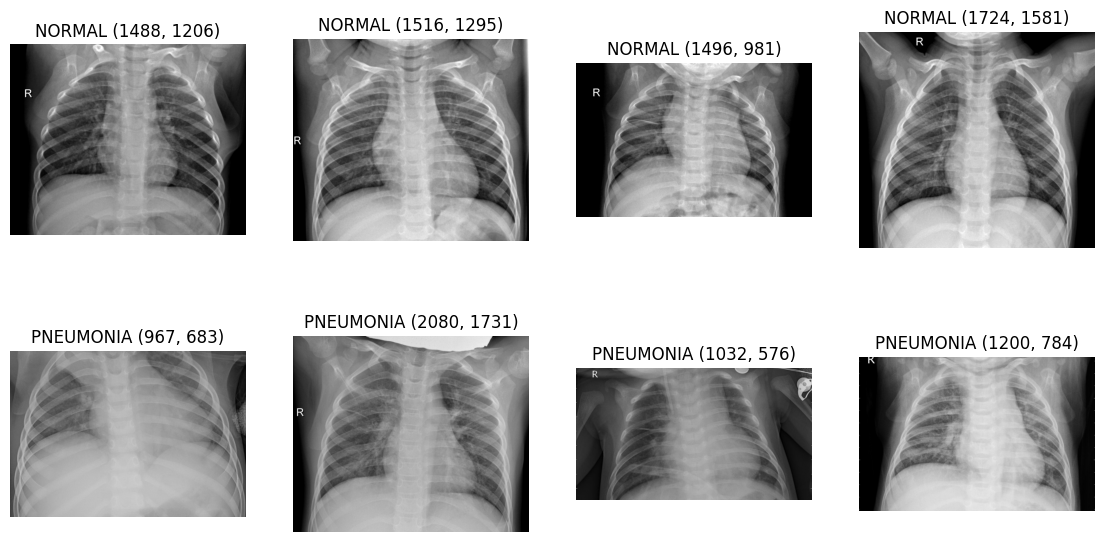

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, label in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = os.path.join(base, "train", label)
    files = os.listdir(folder)[:4]
    for j, name in enumerate(files):
        img = Image.open(os.path.join(folder, name))
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].set_title(f"{label} {img.size}")
        axes[i, j].axis("off")

plt.show()

In [ ]:
n_normal = 1341
n_pneu = 3875
total = n_normal + n_pneu

print("Total train:", total)
print("NORMAL %:", round(n_normal / total * 100, 1))
print("PNEUMONIA %:", round(n_pneu / total * 100, 1))
print("Baseline accuracy on test:", round(390 / 624 * 100, 1))

Total train: 5216
NORMAL %: 25.7
PNEUMONIA %: 74.3
Baseline accuracy on test: 62.5


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

rows = []
for split in ["train", "val"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(base, split, label)
        for name in os.listdir(folder):
            if name.lower().endswith((".jpeg", ".jpg", ".png")):
                rows.append((os.path.join(folder, name), label))

df = pd.DataFrame(rows, columns=["path", "label"])
print(df.shape)
print(df["label"].value_counts())

(5232, 2)
label
PNEUMONIA    3883
NORMAL       1349
Name: count, dtype: int64


In [ ]:
train_df, val_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=42
)

print(len(train_df), len(val_df))
print(train_df["label"].value_counts(normalize=True))
print(val_df["label"].value_counts(normalize=True))

4185 1047
label
PNEUMONIA    0.742174
NORMAL       0.257826
Name: proportion, dtype: float64
label
PNEUMONIA    0.74212
NORMAL       0.25788
Name: proportion, dtype: float64


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH = 32
class_map = {"NORMAL": 0, "PNEUMONIA": 1}

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

In [ ]:
def make_dataset(df, training):
    paths = df["path"].values
    labels = df["label"].map(class_map).values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(df), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

In [ ]:
n_normal = (train_df["label"] == "NORMAL").sum()
n_pneu = (train_df["label"] == "PNEUMONIA").sum()
total = len(train_df)

class_weight = {
    0: total / (2 * n_normal),
    1: total / (2 * n_pneu),
}
print(class_weight)

{0: np.float64(1.9392956441149212), 1: np.float64(0.6736960721184804)}


In [ ]:
images, labels = next(iter(train_ds))
print(images.shape, labels.shape)
print(images.numpy().min(), images.numpy().max())

(32, 224, 224, 3) (32,)
0.0 255.0


In [ ]:
model = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),
    data_augmentation,
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,792,609 (10.65 MB)

 Trainable params: 2,792,609 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision"),
    ],
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=7,
    class_weight=class_weight,
)

Epoch 1/7
131/131 ━━━━━━━━━━━━━━━━━━━━ 323s 2s/step - accuracy: 0.7620 - loss: 0.4478 - precision: 0.9261 - recall: 0.7382 - val_accuracy: 0.9370 - val_loss: 0.1579 - val_precision: 0.9472 - val_recall: 0.9691
Epoch 2/7
131/131 ━━━━━━━━━━━━━━━━━━━━ 318s 2s/step - accuracy: 0.8741 - loss: 0.2943 - precision: 0.9587 - recall: 0.8677 - val_accuracy: 0.9360 - val_loss: 0.1712 - val_precision: 0.9837 - val_recall: 0.9292
Epoch 3/7
131/131 ━━━━━━━━━━━━━━━━━━━━ 292s 2s/step - accuracy: 0.9104 - loss: 0.2324 - precision: 0.9730 - recall: 0.9044 - val_accuracy: 0.9284 - val_loss: 0.1652 - val_precision: 0.9889 - val_recall: 0.9138
Epoch 4/7
131/131 ━━━━━━━━━━━━━━━━━━━━ 319s 2s/step - accuracy: 0.9178 - loss: 0.2127 - precision: 0.9742 - recall: 0.9134 - val_accuracy: 0.9456 - val_loss: 0.1295 - val_precision: 0.9878 - val_recall: 0.9382
Epoch 5/7
131/131 ━━━━━━━━━━━━━━━━━━━━ 313s 2s/step - accuracy: 0.9276 - loss: 0.1918 - precision: 0.9769 - recall: 0.9243 - val_accuracy: 0.9618 - val_loss: 0.

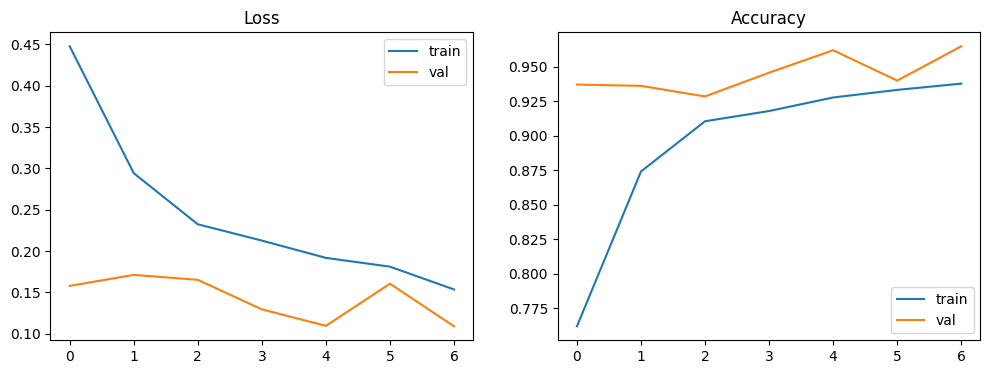

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.legend()

plt.show()

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 324s 2s/step - accuracy: 0.9422 - loss: 0.1407 - precision: 0.9809 - recall: 0.9404 - val_accuracy: 0.9580 - val_loss: 0.1116 - val_precision: 0.9906 - val_recall: 0.9524
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 312s 2s/step - accuracy: 0.9393 - loss: 0.1581 - precision: 0.9801 - recall: 0.9372 - val_accuracy: 0.9580 - val_loss: 0.1074 - val_precision: 0.9919 - val_recall: 0.9511
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 314s 2s/step - accuracy: 0.9446 - loss: 0.1455 - precision: 0.9829 - recall: 0.9417 - val_accuracy: 0.9685 - val_loss: 0.0967 - val_precision: 0.9895 - val_recall: 0.9678
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 313s 2s/step - accuracy: 0.9505 - loss: 0.1379 - precision: 0.9849 - recall: 0.9478 - val_accuracy: 0.9503 - val_loss: 0.1354 - val_precision: 0.9959 - val_recall: 0.9369
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 316s 2s/step - accuracy: 0.9517 - loss: 0.1264 - precision: 0.9837 - recall: 0.9507 - val_accuracy: 0.9599 - val_loss: 0.

In [ ]:
test_rows = []
for label in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(base, "test", label)
    for name in os.listdir(folder):
        if name.lower().endswith((".jpeg", ".jpg", ".png")):
            test_rows.append((os.path.join(folder, name), label))

test_df = pd.DataFrame(test_rows, columns=["path", "label"])
test_ds = make_dataset(test_df, training=False)
print(len(test_df))

624


In [ ]:
model.evaluate(test_ds)

y_true = test_df["label"].map(class_map).values
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 671ms/step - accuracy: 0.8462 - loss: 0.3673 - precision: 0.8128 - recall: 0.9795
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 621ms/step


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))

[[146  88]
 [  8 382]]
              precision    recall  f1-score   support

      NORMAL       0.95      0.62      0.75       234
   PNEUMONIA       0.81      0.98      0.89       390

    accuracy                           0.85       624
   macro avg       0.88      0.80      0.82       624
weighted avg       0.86      0.85      0.84       624



In [ ]:
from sklearn.metrics import roc_auc_score

print("Test AUC:", round(roc_auc_score(y_true, y_prob), 3))

Test AUC: 0.954


In [ ]:
from sklearn.metrics import recall_score

for t in [0.5, 0.7, 0.8, 0.9, 0.95]:
    pred = (y_prob > t).astype(int)
    r_normal = recall_score(y_true, pred, pos_label=0)
    r_pneu = recall_score(y_true, pred, pos_label=1)
    print(t, "NORMAL recall:", round(r_normal, 2), "PNEUMONIA recall:", round(r_pneu, 2))

0.5 NORMAL recall: 0.62 PNEUMONIA recall: 0.98
0.7 NORMAL recall: 0.79 PNEUMONIA recall: 0.95
0.8 NORMAL recall: 0.84 PNEUMONIA recall: 0.93
0.9 NORMAL recall: 0.89 PNEUMONIA recall: 0.89
0.95 NORMAL recall: 0.94 PNEUMONIA recall: 0.82


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

tl_model = tf.keras.Model(inputs, outputs)
tl_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision"),
    ],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_tl = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 358s 3s/step - accuracy: 0.8139 - loss: 0.4015 - precision: 0.9267 - recall: 0.8136 - val_accuracy: 0.9436 - val_loss: 0.1834 - val_precision: 0.9476 - val_recall: 0.9781
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 333s 3s/step - accuracy: 0.9216 - loss: 0.2115 - precision: 0.9770 - recall: 0.9160 - val_accuracy: 0.9532 - val_loss: 0.1467 - val_precision: 0.9596 - val_recall: 0.9781
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 331s 3s/step - accuracy: 0.9238 - loss: 0.1865 - precision: 0.9767 - recall: 0.9192 - val_accuracy: 0.9570 - val_loss: 0.1306 - val_precision: 0.9704 - val_recall: 0.9717
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 333s 3s/step - accuracy: 0.9309 - loss: 0.1688 - precision: 0.9812 - recall: 0.9247 - val_accuracy: 0.9570 - val_loss: 0.1184 - val_precision: 0.9741 - val_recall: 0.9678
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 334s 3s/step - accuracy: 0.9367 - loss: 0.1566 - precision: 0.9853 - recall: 0.9285 - val_accuracy: 0.9570 - val_los

In [ ]:
y_prob_tl = tl_model.predict(test_ds).ravel()
y_pred_tl = (y_prob_tl > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred_tl))
print(classification_report(y_true, y_pred_tl, target_names=["NORMAL", "PNEUMONIA"]))
print("Test AUC:", round(roc_auc_score(y_true, y_prob_tl), 3))

20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step
[[134 100]
 [  4 386]]
              precision    recall  f1-score   support

      NORMAL       0.97      0.57      0.72       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624

Test AUC: 0.962


In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable weight tensors:", len(tl_model.trainable_weights))

Trainable weight tensors: 34


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_ft = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 337s 3s/step - accuracy: 0.9529 - loss: 0.1196 - precision: 0.9863 - recall: 0.9498 - val_accuracy: 0.9647 - val_loss: 0.0992 - val_precision: 0.9830 - val_recall: 0.9691
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 335s 3s/step - accuracy: 0.9448 - loss: 0.1315 - precision: 0.9835 - recall: 0.9414 - val_accuracy: 0.9637 - val_loss: 0.1041 - val_precision: 0.9660 - val_recall: 0.9858
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.9513 - loss: 0.1286 - precision: 0.9856 - recall: 0.9482 - val_accuracy: 0.9608 - val_loss: 0.0984 - val_precision: 0.9730 - val_recall: 0.9743
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 357s 3s/step - accuracy: 0.9484 - loss: 0.1209 - precision: 0.9875 - recall: 0.9424 - val_accuracy: 0.9656 - val_loss: 0.0959 - val_precision: 0.9781 - val_recall: 0.9755
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 338s 3s/step - accuracy: 0.9479 - loss: 0.1228 - precision: 0.9852 - recall: 0.9440 - val_accuracy: 0.9675 - val_los

In [ ]:
y_prob_ft = tl_model.predict(test_ds).ravel()
y_pred_ft = (y_prob_ft > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred_ft))
print(classification_report(y_true, y_pred_ft, target_names=["NORMAL", "PNEUMONIA"]))
print("Test AUC:", round(roc_auc_score(y_true, y_prob_ft), 3))

20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step
[[127 107]
 [  4 386]]
              precision    recall  f1-score   support

      NORMAL       0.97      0.54      0.70       234
   PNEUMONIA       0.78      0.99      0.87       390

    accuracy                           0.82       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.85      0.82      0.81       624

Test AUC: 0.962


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/xray_project"
os.makedirs(save_dir, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


NameError: name 'os' is not defined

In [ ]:
train_df.to_csv(f"{save_dir}/train_df.csv", index=False)
val_df.to_csv(f"{save_dir}/val_df.csv", index=False)
test_df.to_csv(f"{save_dir}/test_df.csv", index=False)

NameError: name 'train_df' is not defined

In [ ]:
model.save(f"{save_dir}/cnn_scratch.keras")
tl_model.save(f"{save_dir}/mobilenet_tl.keras")

NameError: name 'model' is not defined

In [ ]:
import numpy as np
import json

np.savez(
    f"{save_dir}/predictions.npz",
    y_true=y_true,
    y_prob_cnn=y_prob,
    y_prob_tl=y_prob_tl,
    y_prob_ft=y_prob_ft,
)

with open(f"{save_dir}/histories.json", "w") as f:
    json.dump({"cnn": history.history, "tl": history_tl.history, "ft": history_ft.history}, f)

NameError: name 'y_true' is not defined

In [ ]:
!cp chest-xray-pneumonia.zip /content/drive/MyDrive/xray_project/

cp: cannot stat 'chest-xray-pneumonia.zip': No such file or directory


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
save_dir = "/content/drive/MyDrive/xray_project"

!cp {save_dir}/chest-xray-pneumonia.zip /content/
!unzip -q /content/chest-xray-pneumonia.zip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

base = "chest_xray"
IMG_SIZE = (224, 224)
BATCH = 32
class_map = {"NORMAL": 0, "PNEUMONIA": 1}

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_dataset(df, training):
    paths = df["path"].values
    labels = df["label"].map(class_map).values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(df), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

In [ ]:
train_df = pd.read_csv(f"{save_dir}/train_df.csv")
val_df = pd.read_csv(f"{save_dir}/val_df.csv")
test_df = pd.read_csv(f"{save_dir}/test_df.csv")

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

y_true = test_df["label"].map(class_map).values

n_normal = (train_df["label"] == "NORMAL").sum()
n_pneu = (train_df["label"] == "PNEUMONIA").sum()
total = len(train_df)
class_weight = {0: total / (2 * n_normal), 1: total / (2 * n_pneu)}

In [ ]:
model = tf.keras.models.load_model(f"{save_dir}/cnn_scratch.keras")
tl_model = tf.keras.models.load_model(f"{save_dir}/mobilenet_tl.keras")

preds = np.load(f"{save_dir}/predictions.npz")
y_prob = preds["y_prob_cnn"]
y_prob_tl = preds["y_prob_tl"]
y_prob_ft = preds["y_prob_ft"]

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 70 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


False alarms: 107


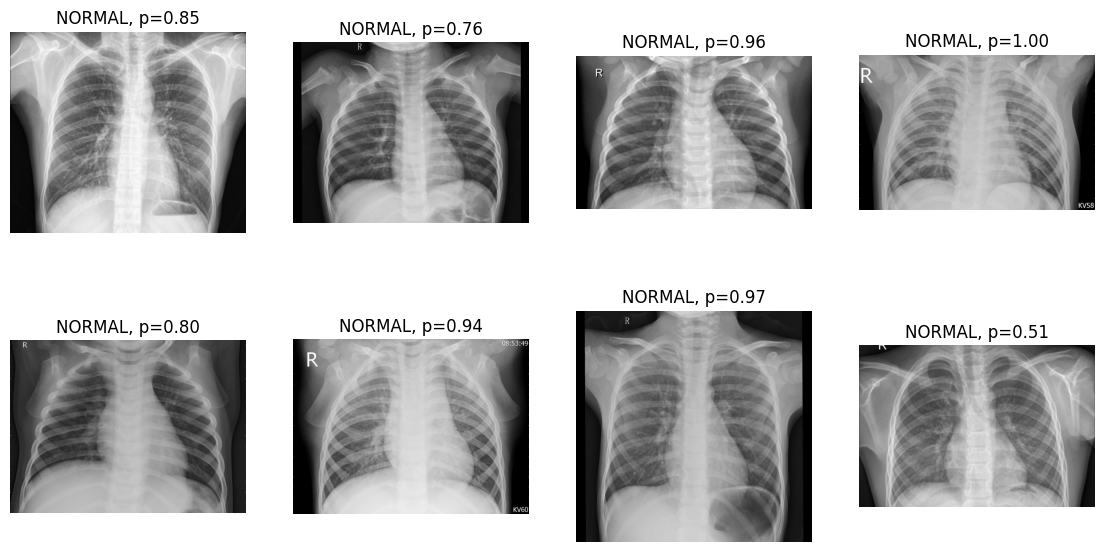

In [ ]:
from PIL import Image

y_pred_ft = (y_prob_ft > 0.5).astype(int)
fp_idx = np.where((y_true == 0) & (y_pred_ft == 1))[0]
print("False alarms:", len(fp_idx))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.ravel(), fp_idx[:8]):
    row = test_df.iloc[idx]
    ax.imshow(Image.open(row["path"]), cmap="gray")
    ax.set_title(f"NORMAL, p={y_prob_ft[idx]:.2f}")
    ax.axis("off")
plt.show()

In [ ]:
def mean_brightness(sub_df, n=100):
    vals = []
    for p in sub_df["path"].sample(n, random_state=0):
        img = Image.open(p).convert("L").resize((64, 64))
        vals.append(np.array(img).mean())
    return np.mean(vals)

for name, d in [("train", train_df), ("test", test_df)]:
    for label in ["NORMAL", "PNEUMONIA"]:
        sub = d[d["label"] == label]
        print(name, label, round(mean_brightness(sub), 1))

train NORMAL 122.4
train PNEUMONIA 125.7
test NORMAL 124.5
test PNEUMONIA 119.3


In [ ]:
def load_image_cropped(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    h = tf.shape(img)[0]
    w = tf.shape(img)[1]
    img = tf.image.crop_to_bounding_box(img, h // 10, w // 10, h * 8 // 10, w * 8 // 10)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

In [ ]:
paths = test_df["path"].values
labels = test_df["label"].map(class_map).values.astype("float32")

test_crop_ds = (
    tf.data.Dataset.from_tensor_slices((paths, labels))
    .map(load_image_cropped, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH)
    .prefetch(tf.data.AUTOTUNE)
)

y_prob_crop = tl_model.predict(test_crop_ds).ravel()
y_pred_crop = (y_prob_crop > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred_crop))
print("AUC:", round(roc_auc_score(y_true, y_prob_crop), 3))

20/20 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step
[[ 36 198]
 [  1 389]]
AUC: 0.945


In [ ]:
strong_aug = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom((-0.3, 0.3)),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
])

In [ ]:
base2 = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base2.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = strong_aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base2(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

tl2_model = tf.keras.Model(inputs, outputs)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
tl2_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision"),
    ],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_tl2 = tl2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 328s 2s/step - accuracy: 0.9171 - loss: 0.1980 - precision: 0.9723 - recall: 0.9144 - val_accuracy: 0.9446 - val_loss: 0.1311 - val_precision: 0.9813 - val_recall: 0.9434
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 324s 2s/step - accuracy: 0.9183 - loss: 0.1806 - precision: 0.9782 - recall: 0.9102 - val_accuracy: 0.9503 - val_loss: 0.1231 - val_precision: 0.9653 - val_recall: 0.9678
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.9152 - loss: 0.1979 - precision: 0.9741 - recall: 0.9099 - val_accuracy: 0.9503 - val_loss: 0.1261 - val_precision: 0.9751 - val_recall: 0.9575
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 284s 2s/step - accuracy: 0.9171 - loss: 0.1977 - precision: 0.9762 - recall: 0.9105 - val_accuracy: 0.9522 - val_loss: 0.1238 - val_precision: 0.9752 - val_recall: 0.9601
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.9123 - loss: 0.2034 - precision: 0.9695 - recall: 0.9105 - val_accuracy: 0.9503 - val_loss: 0.

In [ ]:
y_prob_tl2 = tl2_model.predict(test_ds).ravel()
y_pred_tl2 = (y_prob_tl2 > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred_tl2))
print(classification_report(y_true, y_pred_tl2, target_names=["NORMAL", "PNEUMONIA"]))
print("Test AUC:", round(roc_auc_score(y_true, y_prob_tl2), 3))

20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step
[[120 114]
 [  4 386]]
              precision    recall  f1-score   support

      NORMAL       0.97      0.51      0.67       234
   PNEUMONIA       0.77      0.99      0.87       390

    accuracy                           0.81       624
   macro avg       0.87      0.75      0.77       624
weighted avg       0.85      0.81      0.79       624

Test AUC: 0.956


In [ ]:
def predict_image(path, chosen_model):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    batch = tf.expand_dims(img, axis=0)
    prob = float(chosen_model.predict(batch, verbose=0)[0][0])
    return prob

In [ ]:
from PIL import Image

def show_prediction(path, chosen_model, true_label=None):
    prob = predict_image(path, chosen_model)
    label = "PNEUMONIA" if prob > 0.5 else "NORMAL"
    plt.imshow(Image.open(path), cmap="gray")
    plt.axis("off")
    title = f"Prediction: {label} (p={prob:.2f})"
    if true_label is not None:
        title += f" | True: {true_label}"
    plt.title(title)
    plt.show()

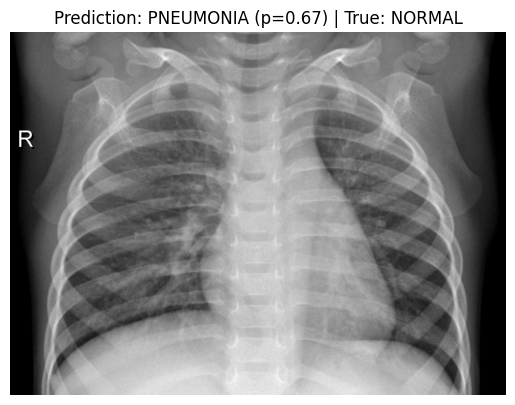

In [ ]:
#@title Random test image
model_choice = "CNN from scratch" #@param ["CNN from scratch", "MobileNetV2 fine-tuned"]
true_class = "NORMAL" #@param ["NORMAL", "PNEUMONIA"]

chosen = model if model_choice == "CNN from scratch" else tl_model
row = test_df[test_df["label"] == true_class].sample(1).iloc[0]
show_prediction(row["path"], chosen, true_label=row["label"])

In [ ]:
def compare_models(path, true_label):
    p_cnn = predict_image(path, model)
    p_tl = predict_image(path, tl_model)
    plt.imshow(Image.open(path), cmap="gray")
    plt.axis("off")
    plt.title(f"True: {true_label}\nCNN p={p_cnn:.2f} | MobileNet p={p_tl:.2f}")
    plt.show()

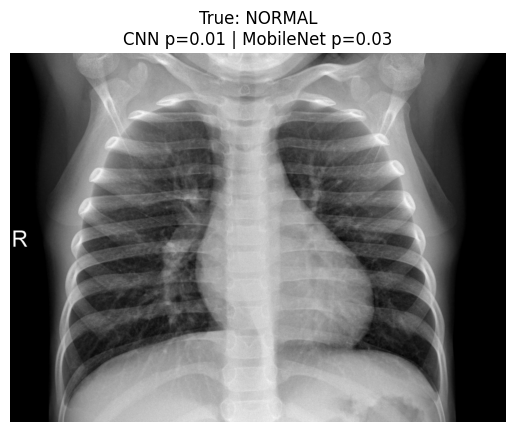

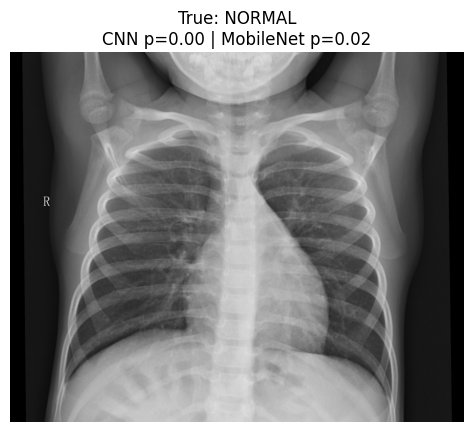

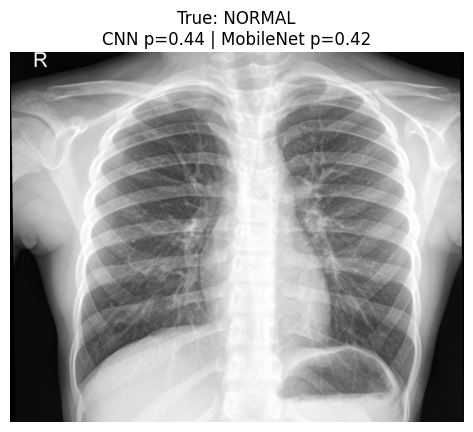

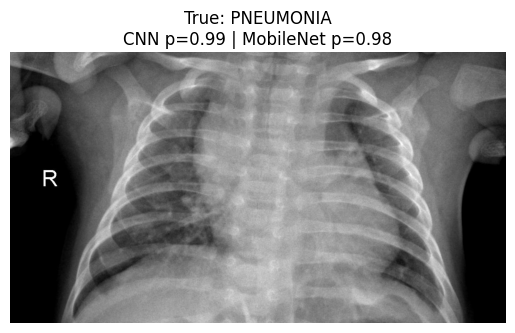

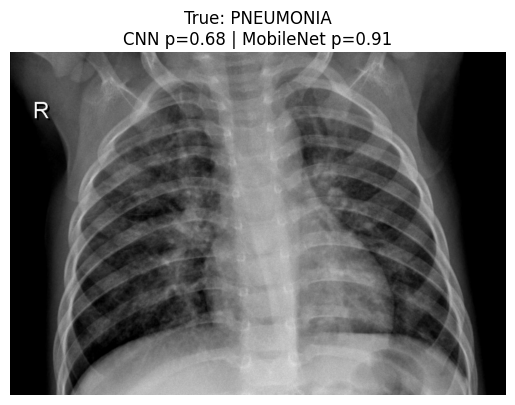

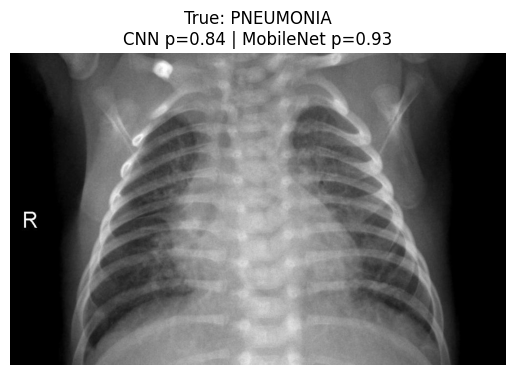

In [ ]:
sample = pd.concat([
    test_df[test_df["label"] == "NORMAL"].sample(3),
    test_df[test_df["label"] == "PNEUMONIA"].sample(3),
])

for _, row in sample.iterrows():
    compare_models(row["path"], row["label"])